In [1]:
import pandas as pd
import math
from sys import float_info
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, wilcoxon, ttest_rel, pearsonr
from numpy import std
import numpy as np
#TODO fix Gopstein17b

In [2]:
def lk_to_dict(lk): 
    lk_arr = lk.strip("[]").split("], [")
    dict = {}
    for l in lk_arr: 
        key, val = l.split(", ")
        dict[int(key)] = float(val)
    return(dict)
def loss_from_df(df): 
    correct_labels = df["correct"]
    answer = df["answer"]
    likelihoods = df["likelihoods"]
    eval_loss = 0
    count = 0
    curr_iter = -1
    prob = 1
    losses = []
    tokens = []
    curr_tokens = []
    for label, iter, lk in zip(correct_labels, answer, likelihoods):  
        lbl, atkn = label.strip("[]").split(",")
        lk_dict = lk_to_dict(lk)
        if curr_iter == -1: 
            curr_iter = iter
        if curr_iter == iter : 
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob *= p
            curr_tokens.append([lbl, atkn])
        else: 
            if prob == 0: 
                    eval_loss += -math.log(float_info.min)
                    losses.append(-math.log(float_info.min))
            else:
                    eval_loss += -math.log(prob)
                    losses.append(-math.log(prob))
            tokens.append(curr_tokens)
            curr_tokens = [[lbl, atkn]]
            count += 1
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob = p
            curr_iter = iter
    if prob == 0: 
        eval_loss += -math.log(float_info.min)
        losses.append(-math.log(float_info.min))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    elif prob != 1:
        eval_loss += -math.log(prob)
        losses.append(-math.log(prob))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    count += 1
    tokens.append(curr_tokens)
    curr_tokens = []
    return(losses, tokens)


In [3]:
def get_values(study, model, variant = "no_order"): 
    answer_amounts = pd.read_csv(f"answer_amounts/{study}.csv")
    result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
    amount_sum = 0
    for i in range(len(answer_amounts)):
        task = answer_amounts["task"].iloc[i]
        answer = answer_amounts["answer"].iloc[i]
        amount = answer_amounts["amount"].iloc[i]
        answer_num = answer_amounts["answer_num"].iloc[i]
        if study == "Gopstein17b" and (task == "task_g" or task == "task_h"):
            continue 
        answer_df = pd.read_csv(f"full_results/{model}/{study}_{variant}/{study}_{variant[:-1]}_{task}_{answer_num}.csv")
        losses, tokens = loss_from_df(answer_df)
        for i in range(amount):
            for loss, token in zip(losses, tokens):
                if study == "Ajami18"and losses== [0.0]: 
                    continue
                result_dict["loss"].append(loss)
                result_dict["task"].append(task)
                result_dict["answer"].append(answer)
                result_dict["tokens"].append(token)
                result_dict["study"].append(study)
                result_dict["model"].append(model)
    return(result_dict)

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Medeiros19", "Siegmund17", "Peitek18"]
result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
models = ["Centaur", "Llama"]
for study in studies: 
    for model in models: 
        print(study, model)
        data_dict = get_values(study, model, "no_order_no_snippets")
        for key in result_dict:
            result_dict[key] += data_dict[key]
result_df = pd.DataFrame(result_dict)

Ajami18 Centaur
Ajami18 Llama
Bauer19 Centaur
Bauer19 Llama
Börstler16 Centaur
Börstler16 Llama
Buse10 Centaur
Buse10 Llama
Gopstein17a Centaur
Gopstein17a Llama
Gopstein17b Centaur
Gopstein17b Llama
Medeiros19 Centaur
Medeiros19 Llama
Peitek17 Centaur
Peitek17 Llama
Peitek18b Centaur
Peitek18b Llama


In [5]:
def get_losses(study, df, model): 
    model_data = df[df["model"] == model]
    study_data = model_data[model_data["study"] == study]
    losses = []
    ids = []
    for i in range(len(study_data)):
        losses.append(study_data["loss"].iloc[i])
        ids.append([study_data["task"].iloc[i], study_data["answer"].iloc[i]])
    return losses, ids
def evaluate_study(study, df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses, ids = get_losses(study, df, model)
        ids_arrs.append(ids)
        losses_dict[model] = losses
        res_dict[f"{model}_mean"] = np.mean(losses)
        res_dict[f"{model}_std"] = np.std(losses)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = study
    return(res_dict)
def eval_all(df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses_all = []
        ids_all = []
        for study in studies:
            losses, ids = get_losses(study, df, model)
            losses_all += losses
            ids_all+= ids
        ids_arrs.append(ids_all)
        print(len(losses_all))
        losses_dict[model] = losses_all
        res_dict[f"{model}_mean"] = np.mean(losses_all)
        res_dict[f"{model}_std"] = np.std(losses_all)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses_all)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = "overall"
    return(res_dict)

In [6]:
all_res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
for study in studies: 
    study_res_dict = evaluate_study(study, result_df)
    for key in all_res_dict:
        all_res_dict[key].append(study_res_dict[key])
study_res_dict = eval_all(result_df)
for key in study_res_dict:
    all_res_dict[key].append(study_res_dict[key])
all_res_df = pd.DataFrame(all_res_dict)
all_res_df.to_csv("results/results_RQ2_no_order_no_snippets.csv", index=False)
result_df.to_csv("results/data_RQ2_no_order_no_snippets.csv", index=False)

25554
25554


Ajami18: 2067 Trials
Centaur mean: 3.920263232944759, STD: 3.123526891684754
Llama mean: 3.840822996469585, STD: 3.050431974463089
T-test statistic: 5.678264252885225, p-value: 1.5529206774275165e-08, cohen's d: 0.12489508887369188


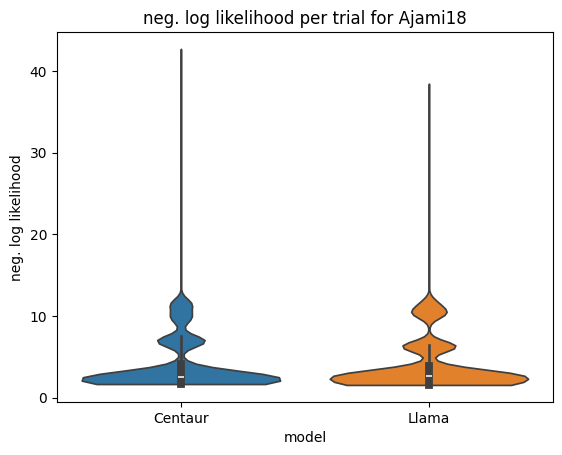

Bauer19: 88 Trials
Centaur mean: 9.479939737911238, STD: 8.894099972951759
Llama mean: 10.582918434295555, STD: 10.633722371388188
T-test statistic: -5.563275649632939, p-value: 2.876600461693841e-07, cohen's d: -0.5930471768927333


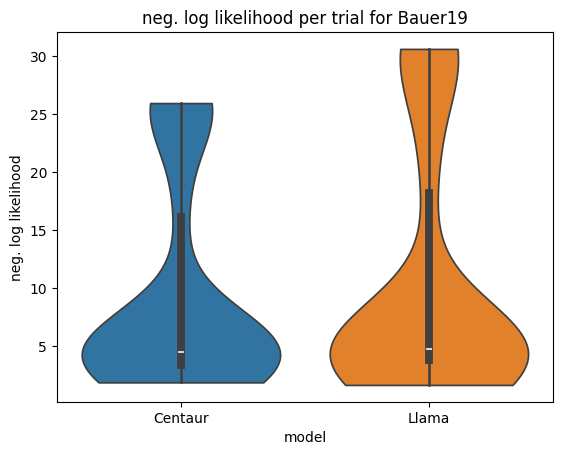

Börstler16: 2598 Trials
Centaur mean: 11.203204632034227, STD: 14.442879877706114
Llama mean: 12.017828447804103, STD: 14.183623930179548
T-test statistic: -16.322319863955176, p-value: 4.321773006250417e-57, cohen's d: -0.32023021798404655


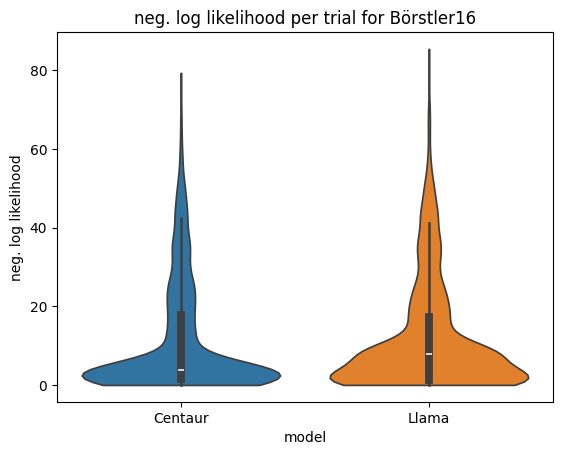

Buse10: 12100 Trials
Centaur mean: 1.7340274364035047, STD: 0.3929655200969317
Llama mean: 2.1172772212415496, STD: 0.6175737263536237
T-test statistic: -84.72339789097364, p-value: 0.0, cohen's d: -0.7702127080997604


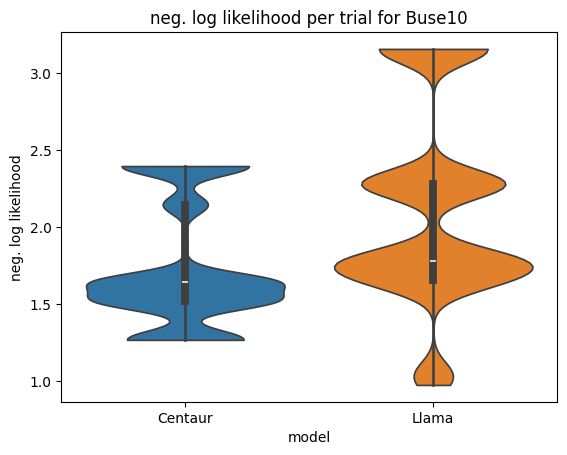

Gopstein17a: 6069 Trials
Centaur mean: 5.924241588819025, STD: 3.1865643454968513
Llama mean: 6.607116036473228, STD: 3.6897619469278125
T-test statistic: -43.88903714109056, p-value: 0.0, cohen's d: -0.5633748876128172


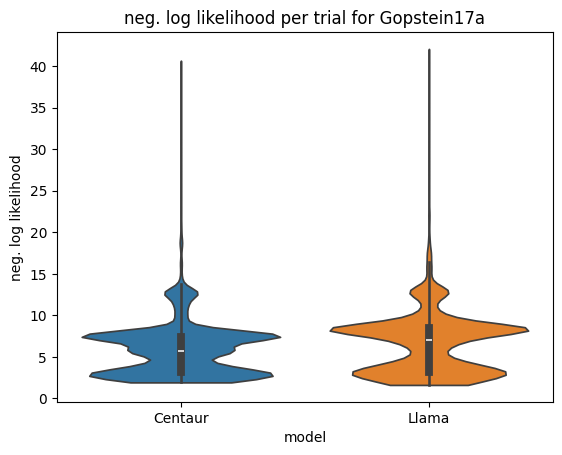

Gopstein17b: 498 Trials
Centaur mean: 10.460955872679905, STD: 9.111317765572306
Llama mean: 11.14027266490329, STD: 10.230137965448728
T-test statistic: -8.118822440281198, p-value: 3.7360098302085304e-15, cohen's d: -0.36381313282520666


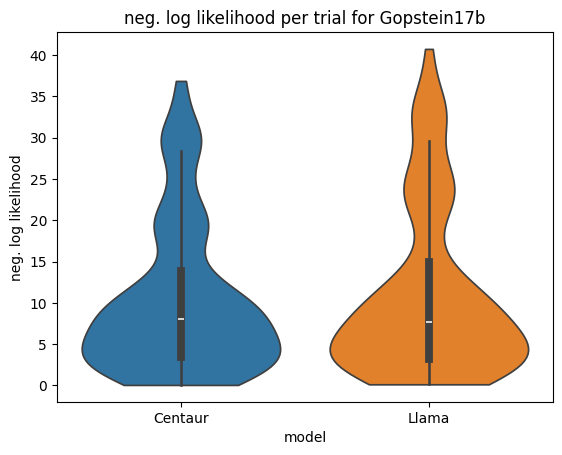

Medeiros19: 1164 Trials
Centaur mean: 1.738271194913172, STD: 0.3035624632844288
Llama mean: 1.8573245087296877, STD: 0.43086403872679
T-test statistic: -8.946440146231353, p-value: 1.4162922685797715e-18, cohen's d: -0.2622248046760093


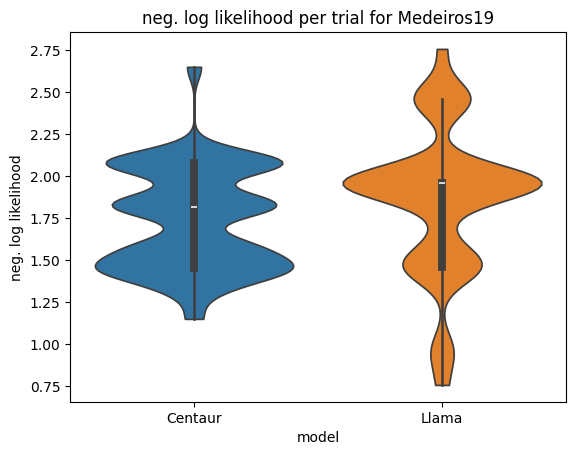

Peitek17: 420 Trials
Centaur mean: 0.7425779542833099, STD: 0.5180280358988198
Llama mean: 1.093493137199932, STD: 0.9859307202046489
T-test statistic: -10.96016094788147, p-value: 9.504885236043728e-25, cohen's d: -0.5348010934282595


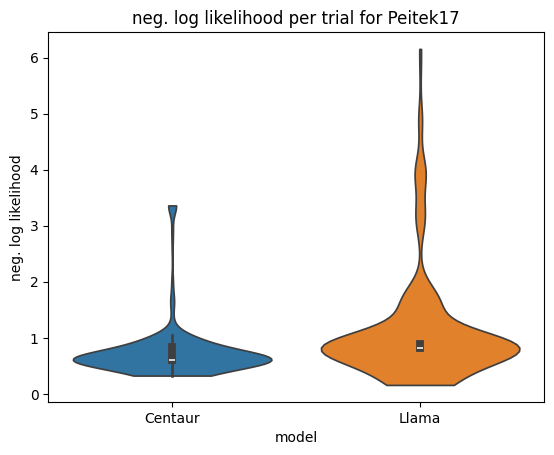

Peitek18b: 550 Trials
Centaur mean: 1.6673375253131437, STD: 0.6943626162107226
Llama mean: 1.6954600647408515, STD: 1.0655367075442999
T-test statistic: -0.8898944636882191, p-value: 0.3739123372956139, cohen's d: -0.037945227427844015


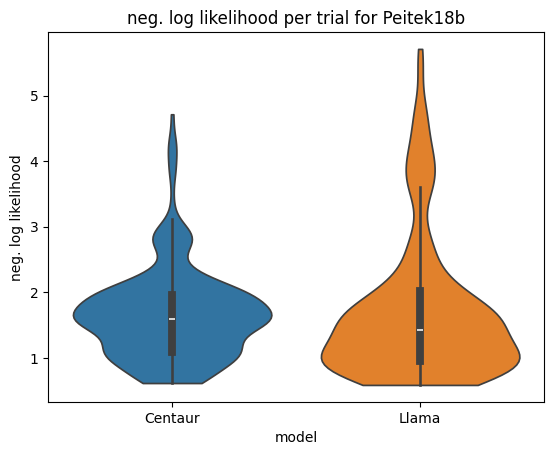

overall: 25554 Trials
Centaur mean: 4.047942423560998, STD: 6.0345648698173155
Llama mean: 4.496822005721574, STD: 6.187572561433527
T-test statistic: -62.29061264364272, p-value: 0.0, cohen's d: -0.38966657749741207


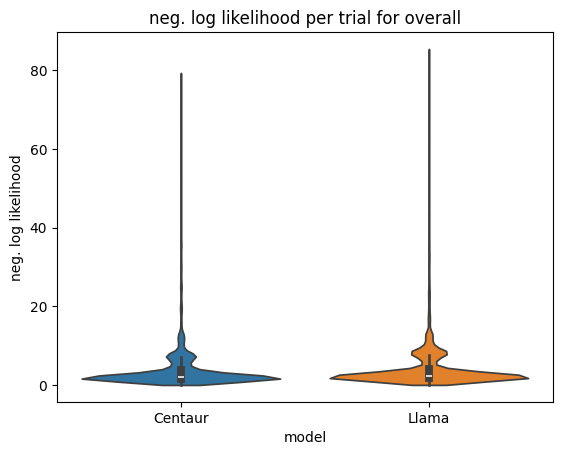

In [7]:
#TODO Violinplots & Eval
import seaborn as sns

variant = "RQ2_no_order_no_snippets"
for study in studies: 
    study_data_df = result_df[result_df["study"]==study]
    study_result_df = all_res_df[all_res_df["study"]==study]
    print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
    print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
    print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
    print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
    sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
    plt.ylabel("neg. log likelihood")
    plt.title(f"neg. log likelihood per trial for {study}")
    plt.savefig(f"images/{study}_violin_{variant}.png")
    plt.show()
    plt.close()
study = "overall"
study_data_df = result_df
study_result_df = all_res_df[all_res_df["study"]==study]
print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
plt.ylabel("neg. log likelihood")
plt.title(f"neg. log likelihood per trial for {study}")
plt.savefig(f"images/{study}_violin_{variant}.png")
plt.show()
plt.close()